# Title

**Exercise 1 - Basic Multi-classification**

# Description
The goal of the exercise is to get comfortable using multiclass classification models.  Eventually, you will produce a plot similar to the one given below:


<img src="../img/image.png" style="width: 500px;">

# Instructions: 
We are trying to predict the types of Irises in the classic <a href="https://en.wikipedia.org/wiki/Iris_flower_data_set" target="_blank">Iris data set</a> based on measured characteristics
- Load the Iris data set and convert to a data frame.
- Fit  multinomial & OvR logistic regressions and a $k$-NN model. 
- Compute the accuracy of the models.
- Plot the classification boundaries against the two predictors used.

# Hints:

<a href="https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.LogisticRegression.html" target="_blank">sklearn.LogisticRegression()</a> : Generates a Logistic Regression classifier

<a href="https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.LogisticRegression.html#sklearn.linear_model.LogisticRegression.fit" target="_blank">sklearn.fit()</a> : Fits the model to the given data

<a href="https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.LogisticRegression.html#sklearn.linear_model.LogisticRegression.predict" target="_blank">sklearn.predict()</a> : Predict using the estimated model (Logistic or knn classifiers) to perform pure classification predictions

<a href="https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.LogisticRegression.html#sklearn.linear_model.LogisticRegression.predict_proba" target="_blank">sklearn.predict_proba()</a> : Predict using the estimated model (Logistic or knn classifiers) to perform probability predictions of all the classes in the response (they should add up to 1 for each observation)

<a href="https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.LogisticRegression.html" target="_blank">sklearn.LogisticRegression.coef_ and .intercept_</a> : Pull off the estimated $\beta$ coefficients in a Logistic Regression model

<a href="https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.LogisticRegression.html#sklearn.linear_model.LogisticRegression.score" target="_blank">sklearn.score()</a> : Accuracy classification score.

<a href="https://matplotlib.org/3.3.2/api/_as_gen/matplotlib.pyplot.pcolormesh.html" target="_blank">matplotlib.pcolormesh()</a> : Accuracy classification score

**Note: This exercise is auto-graded and you can try multiple attempts.**

In [167]:
%matplotlib inline
from sklearn import datasets
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import numpy as np

In [168]:
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier 



## Irises

Read in the data set and convert to a Pandas data frame:

In [169]:
raw = datasets.load_iris()
iris = pd.DataFrame(raw['data'],columns=raw['feature_names'])
iris['type'] = raw['target'] 
iris.head()

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),type
0,5.1,3.5,1.4,0.2,0
1,4.9,3.0,1.4,0.2,0
2,4.7,3.2,1.3,0.2,0
3,4.6,3.1,1.5,0.2,0
4,5.0,3.6,1.4,0.2,0


Note: this violin plot is 'inverted': putting the response variable in the model on the x-axis.  This is fine for exploration

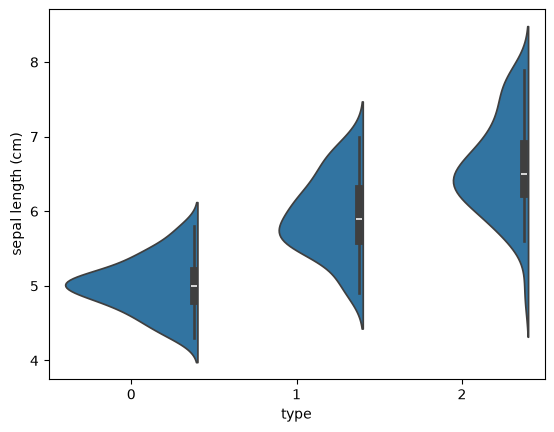

In [170]:
sns.violinplot(y=iris['sepal length (cm)'], x=iris['type'], split=True);

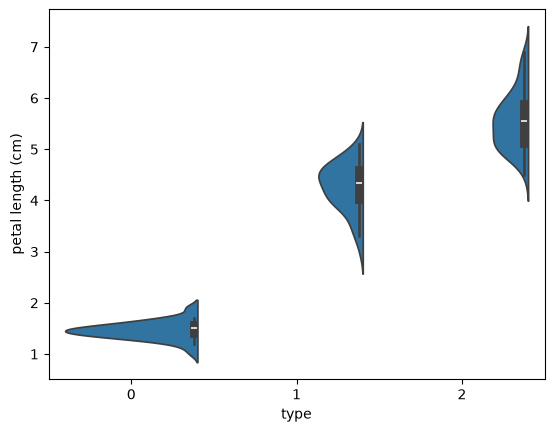

In [171]:
# Create a violin plot to compare petal length 
# across the types of irises

sns.violinplot(y=iris['petal length (cm)'], x=iris['type'], split=True);

Here we fit our first model (the OvR logistic) and print out the coefficients:

In [172]:
logit_ovr = LogisticRegression(multi_class='ovr',max_iter = 1000).fit(
    iris[['sepal length (cm)','sepal width (cm)']], iris['type'])
print(logit_ovr.intercept_)
print(logit_ovr.coef_)


[  8.32315487   5.68615002 -12.52959903]
[[-3.38828053  3.1645602 ]
 [ 0.12717562 -2.38539599]
 [ 2.22195969 -0.51274517]]


In [173]:
# we can predict classes or probabilities
print(logit_ovr.predict(iris[['sepal length (cm)','sepal width (cm)']])[0:5])
print(logit_ovr.predict_proba(iris[['sepal length (cm)','sepal width (cm)']])[0:5])

[0 0 0 0 0]
[[0.84360194 0.11124823 0.04514983]
 [0.69398076 0.27009269 0.03592655]
 [0.80138543 0.178278   0.02033657]
 [0.77760827 0.20572463 0.0166671 ]
 [0.87799483 0.08770916 0.034296  ]]


In [174]:
# and calculate accuracy
print(logit_ovr.score(iris[['sepal length (cm)','sepal width (cm)']],iris['type']))

0.8066666666666666


Now it's your turn: but this time with the multinomial logistic regression.

In [175]:
### edTest(test_multinomial) ###

# Fit the model and print out the coefficients
logit_multi = LogisticRegression(multi_class='multinomial',max_iter = 1000).fit(
    iris[['sepal length (cm)','sepal width (cm)']], iris['type'])
intercept = logit_multi.intercept_
coefs = logit_multi.coef_
print(intercept)
print(coefs)

[ 7.91140003  1.84697777 -9.75837781]
[[-2.70858405  2.32402607]
 [ 0.61260073 -1.57100532]
 [ 2.09598332 -0.75302075]]


In [176]:
### edTest(test_multinomialaccuracy) ###

multi_accuracy = logit_multi.score(iris[['sepal length (cm)','sepal width (cm)']],iris['type'])
print(multi_accuracy)

0.82


c:\Users\biaon\Desktop\DataScience\Section6\.venv\Lib\site-packages\sklearn\base.py:493: UserWarning: X does not have valid feature names, but LogisticRegression was fitted with feature names
  warnings.warn(
c:\Users\biaon\Desktop\DataScience\Section6\.venv\Lib\site-packages\sklearn\base.py:493: UserWarning: X does not have valid feature names, but LogisticRegression was fitted with feature names
  warnings.warn(


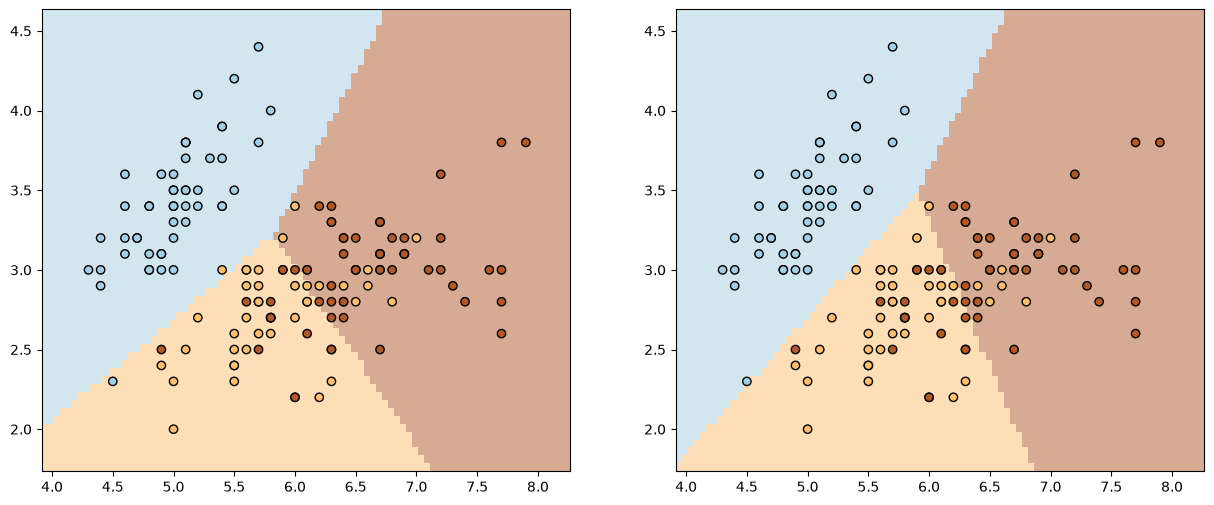

In [177]:
# Plot the decision boundary. 
x1_range = iris['sepal length (cm)'].max() - iris['sepal length (cm)'].min()
x2_range = iris['sepal width (cm)'].max() - iris['sepal width (cm)'].min()
x1_min, x1_max = iris['sepal length (cm)'].min()-0.1*x1_range, iris['sepal length (cm)'].max() +0.1*x1_range
x2_min, x2_max = iris['sepal width (cm)'].min()-0.1*x2_range, iris['sepal width (cm)'].max() + 0.1*x2_range

step = .05 
x1x, x2x = np.meshgrid(np.arange(x1_min, x1_max, step), np.arange(x2_min, x2_max, step))
y_hat_ovr = logit_ovr.predict(np.c_[x1x.ravel(), x2x.ravel()])
y_hat_multi = logit_multi.predict(np.c_[x1x.ravel(), x2x.ravel()])


fig, (ax1, ax2) = plt.subplots(1, 2,  figsize=(15, 6))

ax1.pcolormesh(x1x, x2x, y_hat_ovr.reshape(x1x.shape), cmap=plt.cm.Paired,alpha = 0.5)
ax1.scatter(iris['sepal length (cm)'], iris['sepal width (cm)'], c=iris['type'], edgecolors='k', cmap=plt.cm.Paired)

### your job is to create the same plot, but for the multinomial

ax2.pcolormesh(x1x, x2x, y_hat_multi.reshape(x1x.shape), cmap=plt.cm.Paired,alpha = 0.5)
ax2.scatter(iris['sepal length (cm)'], iris['sepal width (cm)'], c=iris['type'], edgecolors='k', cmap=plt.cm.Paired)


plt.show()

In [178]:
#fit a knn model (k=5) for the same data 
knn5 = KNeighborsClassifier(n_neighbors=5).fit(iris[['sepal length (cm)','sepal width (cm)']], iris['type'])

In [179]:
### edTest(test_knnaccuracy) ###

#Calculate the accuracy
knn5_accuracy = knn5.score(iris[['sepal length (cm)','sepal width (cm)']], iris['type'])
print(knn5_accuracy)

0.8333333333333334


c:\Users\biaon\Desktop\DataScience\Section6\.venv\Lib\site-packages\sklearn\base.py:493: UserWarning: X does not have valid feature names, but KNeighborsClassifier was fitted with feature names
  warnings.warn(


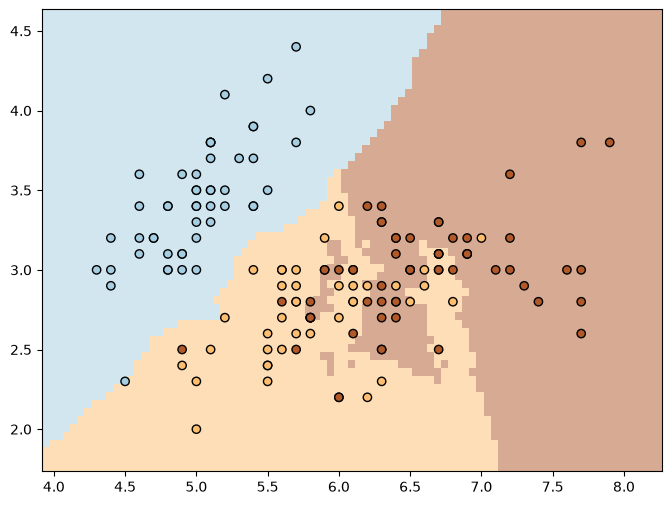

In [180]:
# and plot the classification boundary

y_hat_knn5 = knn5.predict(np.c_[x1x.ravel(), x2x.ravel()])

fig, ax1 = plt.subplots(1, 1,  figsize=(8, 6))

ax1.pcolormesh(x1x, x2x, y_hat_knn5.reshape(x1x.shape), cmap=plt.cm.Paired,alpha = 0.5)
# Plot also the training points
ax1.scatter(iris['sepal length (cm)'], iris['sepal width (cm)'], c=iris['type'], edgecolors='k', cmap=plt.cm.Paired)

plt.show()